# Sign Language Recognition: Transformer Training

Run the cells from top to bottom. This workflow reuses the SX MediaPipe landmark extractor and transformer, caches landmarks for each image split, trains on the train split, selects the best epoch using validation accuracy, saves a checkpoint, and evaluates that checkpoint on the test split.

> **Data limitation:** the current dataset contains still images, not video. Each image supplies one landmark pose; the training dataset synthesizes a short window with small landmark jitter and scale drift. This is useful for experimenting with the transformer input pipeline, but it does not teach real signing motion.

## Step 1: Environment and settings

The expected data layout is `SuXin_TEMP/data/{train,valid,test}/<class>/*image*`. This workflow uses two hand landmark sets plus body-pose landmarks (225 values per image).

In [ ]:
import random
import sys
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import DataLoader

PROJECT_ROOT = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents]
     if (parent / 'models' / 'SX' / 'train.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Could not find models/SX/train.py from the notebook working directory.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from models.SX.train import (
    SignLanguageWindowDataset,
    cache_landmarks,
    load_image_samples,
)
from models.SX.transformer import build_gesture_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_ROOT = PROJECT_ROOT / 'SuXin_TEMP' / 'data'
CACHE_ROOT = PROJECT_ROOT / 'SuXin_TEMP' / 'landmark_cache_transformer'

TWO_HANDS = True
USE_BODY_POSE = True
WINDOW_SIZE = 16
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
D_MODEL = 128
NUM_HEADS = 4
NUM_LAYERS = 2
FEEDFORWARD_DIM = 256
DROPOUT = 0.2
POOLING = 'cls'

if WINDOW_SIZE < 2:
    raise ValueError('The transformer needs WINDOW_SIZE >= 2.')

print(f'Project root: {PROJECT_ROOT}')
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print(f'Data root: {DATA_ROOT}')
print(f'Feature layout: two_hands={TWO_HANDS}, use_body_pose={USE_BODY_POSE}')

Project root: c:\Sean Su\NUS_Project\VisionSpeak
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Ti
Data root: c:\Sean Su\NUS_Project\VisionSpeak\SuXin_TEMP\data
Feature layout: two_hands=True, use_body_pose=False


## Step 2: Load splits and cache landmarks

MediaPipe runs once per image and writes one `features` array per image. This separate cache directory avoids confusing the transformer's cache with the older LSTM notebook cache.

In [4]:
SPLITS = ('train', 'valid', 'test')
samples_by_split = {}
for split in SPLITS:
    split_dir = DATA_ROOT / split
    if not split_dir.is_dir():
        raise FileNotFoundError(f'Missing dataset split: {split_dir}')
    samples_by_split[split] = load_image_samples(split_dir)
    if not samples_by_split[split]:
        raise ValueError(f'No supported image files found under {split_dir}')

class_names = sorted(
    {label for split in ('train', 'valid') for _, label in samples_by_split[split]}
)
class_to_idx = {name: index for index, name in enumerate(class_names)}
unknown_test = sorted({label for _, label in samples_by_split['test']} - set(class_names))
if unknown_test:
    raise ValueError(f'test contains classes absent from train/valid: {unknown_test}')

print(f'Classes ({len(class_names)}): {class_names}')
for split in SPLITS:
    print(f'{split}: {len(samples_by_split[split])} images')

feature_size = (126 if TWO_HANDS else 63) + (99 if USE_BODY_POSE else 0)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
cache_report = {}
for split in SPLITS:
    detected, missing = cache_landmarks(
        samples_by_split[split],
        CACHE_ROOT / split,
        two_hands=TWO_HANDS,
        sequence_length=1,
        use_body_pose=USE_BODY_POSE,
    )
    cache_report[split] = {'detected': detected, 'missing': missing}
    print(f'{split}: detected={detected}, no landmarks={missing}')

print(f'Landmark vector size: {feature_size}')
print(f'Cache directory: {CACHE_ROOT}')

Classes (18): ['apple', 'can', 'get', 'good', 'have', 'help', 'how', 'i', 'like', 'love', 'my', 'no', 'sorry', 'ty', 'want', 'yes', 'you', 'your']
train: 459 images
valid: 45 images
test: 23 images
train: detected=318, no landmarks=141
valid: detected=31, no landmarks=14
test: detected=21, no landmarks=2
Landmark vector size: 126
Cache directory: c:\Sean Su\NUS_Project\VisionSpeak\SuXin_TEMP\landmark_cache_transformer


## Step 3: Build transformer datasets and model settings

Training windows use landmark jitter and dropout plus a small smooth scale drift. Validation and test windows are not augmented. The Transformer receives tensors shaped `(batch, window, features)`; Step 4 initializes a fresh model from these settings on every run.

In [5]:
train_dataset = SignLanguageWindowDataset(
    samples_by_split['train'],
    class_to_idx,
    two_hands=TWO_HANDS,
    window_size=WINDOW_SIZE,
    cache_dir=CACHE_ROOT / 'train',
    use_body_pose=USE_BODY_POSE,
    augment=True,
)
valid_dataset = SignLanguageWindowDataset(
    samples_by_split['valid'],
    class_to_idx,
    two_hands=TWO_HANDS,
    window_size=WINDOW_SIZE,
    cache_dir=CACHE_ROOT / 'valid',
    use_body_pose=USE_BODY_POSE,
    augment=False,
)
test_dataset = SignLanguageWindowDataset(
    samples_by_split['test'],
    class_to_idx,
    two_hands=TWO_HANDS,
    window_size=WINDOW_SIZE,
    cache_dir=CACHE_ROOT / 'test',
    use_body_pose=USE_BODY_POSE,
    augment=False,
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

input_size = feature_size
model_settings = {
    'architecture': 'transformer',
    'input_size': input_size,
    'num_classes': len(class_names),
    'num_layers': NUM_LAYERS,
    'dropout': DROPOUT,
    'window_size': WINDOW_SIZE,
    'sequence_length': WINDOW_SIZE,
    'two_hands': TWO_HANDS,
    'use_body_pose': USE_BODY_POSE,
    'd_model': D_MODEL,
    'num_heads': NUM_HEADS,
    'feedforward_dim': FEEDFORWARD_DIM,
    'pooling': POOLING,
    'max_tokens': WINDOW_SIZE + 1,
}

print(f'Train/valid/test: {len(train_dataset)}/{len(valid_dataset)}/{len(test_dataset)}')
print(f'Input tensor per batch: ({BATCH_SIZE}, {WINDOW_SIZE}, {input_size})')
print(f'Model settings: {model_settings}')

Train/valid/test: 459/45/23
Input tensor per batch: (16, 16, 126)
Model settings: {'architecture': 'transformer', 'input_size': 126, 'num_classes': 18, 'num_layers': 2, 'dropout': 0.2, 'window_size': 16, 'sequence_length': 16, 'two_hands': True, 'use_body_pose': False, 'd_model': 128, 'num_heads': 4, 'feedforward_dim': 256, 'pooling': 'cls', 'max_tokens': 17}


## Step 4: Train and save the best body-plus-hands checkpoint for each epoch budget

This Transformer uses two hand landmark sets plus body-pose landmarks (225 values per image). After setting `USE_BODY_POSE = True`, rerun the setup, landmark-cache, and dataset cells above Step 4 so features and `model_settings` use the body-plus-hands layout. Then run the training cell with `EPOCHS = 50`, change it to `100` and rerun, then change it to `150` and rerun. Each execution starts a fresh Transformer and saves the best validation checkpoint for that run.

The outputs are saved under `checkpoints/retrain`:

- `Sign_Language_MediaPipe_Transformer_50.pt`
- `Sign_Language_MediaPipe_Transformer_100.pt`
- `Sign_Language_MediaPipe_Transformer_150.pt`

The saved `epoch` records when the best validation score occurred; it may be earlier than the epoch limit.

In [ ]:
# Step 4: train from scratch and save the best checkpoint for this epoch budget.
# Run this cell three times, setting EPOCHS to 50, 100, then 150.
EPOCHS = 150
CHECKPOINT_PREFIX = 'Sign_Language_MediaPipe_Transformer'  # Change to customize the filename.
CHECKPOINT_DIR = PROJECT_ROOT / 'checkpoints' / 'retrain'
CHECKPOINT_PATH = CHECKPOINT_DIR / f'{CHECKPOINT_PREFIX}_{EPOCHS}.pt'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Reset randomness and reinitialize so each execution is a fresh, comparable run.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = build_gesture_model(model_settings, num_classes=len(class_names)).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = torch.nn.CrossEntropyLoss()
print(f'Architecture: {model_settings["architecture"]}')
print(f'Feature layout: {feature_size} features per frame, window={WINDOW_SIZE}')
print(f'Training budget: {EPOCHS} epochs')
print(f'Best-checkpoint output: {CHECKPOINT_PATH}')
print(f'Model parameters: {sum(parameter.numel() for parameter in model.parameters()):,}')


def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.set_grad_enabled(training):
        for sequences, labels in loader:
            sequences = sequences.to(DEVICE)
            labels = labels.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(sequences)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += labels.size(0)

    denominator = max(total_samples, 1)
    return total_loss / denominator, total_correct / denominator


best_val_acc = -1.0
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    valid_loss, valid_acc = run_epoch(valid_loader, training=False)
    print(
        f'Epoch {epoch:02d}/{EPOCHS} | '
        f'train loss {train_loss:.4f}, acc {train_acc:.4f} | '
        f'valid loss {valid_loss:.4f}, acc {valid_acc:.4f}'
    )

    if valid_acc > best_val_acc:
        best_val_acc = valid_acc
        best_epoch = epoch
        checkpoint = {
            'model_state_dict': model.state_dict(),
            'class_to_idx': class_to_idx,
            'idx_to_class': {index: name for name, index in class_to_idx.items()},
            'best_val_acc': best_val_acc,
            'epoch': epoch,
            'epoch_limit': EPOCHS,
            **model_settings,
        }
        torch.save(checkpoint, CHECKPOINT_PATH)
        print(f'Saved best checkpoint: {CHECKPOINT_PATH}')

print(f'Best validation accuracy: {best_val_acc:.4f} at epoch {best_epoch}')
print(f'Checkpoint: {CHECKPOINT_PATH}')

Architecture: transformer
Feature layout: 126 features per frame, window=16
Training budget: 150 epochs
Best-checkpoint output: c:\Sean Su\NUS_Project\VisionSpeak\models\SX\Sign_Language_MediaPipe_Transformer_Hand_150.pt
Model parameters: 286,098
Epoch 01/150 | train loss 3.4353, acc 0.0741 | valid loss 3.2797, acc 0.1111
Saved best checkpoint: c:\Sean Su\NUS_Project\VisionSpeak\models\SX\Sign_Language_MediaPipe_Transformer_Hand_150.pt
Epoch 02/150 | train loss 3.0654, acc 0.0915 | valid loss 3.1387, acc 0.1333
Saved best checkpoint: c:\Sean Su\NUS_Project\VisionSpeak\models\SX\Sign_Language_MediaPipe_Transformer_Hand_150.pt
Epoch 03/150 | train loss 2.9041, acc 0.1176 | valid loss 3.0315, acc 0.1333
Epoch 04/150 | train loss 2.8625, acc 0.1176 | valid loss 2.9740, acc 0.0889
Epoch 05/150 | train loss 2.8284, acc 0.1329 | valid loss 2.9587, acc 0.1333
Epoch 06/150 | train loss 2.7301, acc 0.1373 | valid loss 2.8873, acc 0.0889
Epoch 07/150 | train loss 2.5468, acc 0.1983 | valid loss 3

## Step 5: Reload checkpoint and evaluate the test split

Reloading through the SX inference loader verifies that the saved architecture and landmark metadata reconstruct the model correctly.

In [40]:
from models.SX.inference import load_sx_checkpoint

best_model, checkpoint_classes, checkpoint_config = load_sx_checkpoint(CHECKPOINT_PATH, DEVICE)
if checkpoint_classes != class_to_idx:
    raise ValueError('Loaded checkpoint class mapping does not match this notebook run.')

test_loss_total = 0.0
test_correct = 0
test_total = 0
with torch.inference_mode():
    for sequences, labels in test_loader:
        sequences = sequences.to(DEVICE)
        labels = labels.to(DEVICE)
        logits = best_model(sequences)
        loss = criterion(logits, labels)
        test_loss_total += loss.item() * labels.size(0)
        test_correct += (logits.argmax(dim=1) == labels).sum().item()
        test_total += labels.size(0)

test_loss = test_loss_total / max(test_total, 1)
test_accuracy = test_correct / max(test_total, 1)
print(f'Loaded architecture: {checkpoint_config.architecture}')
print(f'Loaded window size: {checkpoint_config.window_size}')
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f} ({test_correct}/{test_total})')
print(f'Saved checkpoint: {CHECKPOINT_PATH}')

Loaded architecture: transformer
Loaded window size: 16
Test loss: 2.2133
Test accuracy: 0.6087 (14/23)
Saved checkpoint: c:\Sean Su\NUS_Project\VisionSpeak\checkpoints\sx_transformer_TwoHand_best.pt


## Interpreting this experiment

The validation and test scores measure recognition of still-image poses under the synthetic-window setup, not recognition of movement. For dynamic word signs, collect labeled video clips with per-frame landmark arrays shaped `(frames, 126)` or `(frames, 225)`, and enumerate training samples by clip.

## Step 6: Live webcam prediction (Mac / Windows)

The next cell defaults to `Sign_Language_MediaPipe_Transformer_150.pt`. Set `CHECKPOINT_EPOCH` to `50` or `100` to select another body-plus-hands run. The checkpoint loader reconstructs the Transformer and reads its hand/body layout and window size from the saved metadata. On macOS, allow camera access to VS Code or the app running Jupyter. Press `q` or `Esc` to stop.

In [ ]:
from collections import deque
import platform

import cv2
import numpy as np
import torch

from models.SX.features import extract_rgb
from models.SX.inference import choose_device, load_sx_checkpoint
from processing.mediapipe_compat import mp

# Choose which body-plus-hands epoch-budget checkpoint to use.
CHECKPOINT_PREFIX = 'Sign_Language_MediaPipe_Transformer'
CHECKPOINT_EPOCH = 150  # Change to 50 or 100 to use another run.
CHECKPOINT_PATH = (
    PROJECT_ROOT / 'checkpoints' / 'retrain'
    / f'{CHECKPOINT_PREFIX}_{CHECKPOINT_EPOCH}.pt'
)

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(
        f'Checkpoint not found: {CHECKPOINT_PATH}. Run the training cell with EPOCHS={CHECKPOINT_EPOCH} first.'
    )

device = choose_device('auto')
webcam_model, class_to_idx_webcam, webcam_config = load_sx_checkpoint(
    CHECKPOINT_PATH,
    device,
)
idx_to_class_webcam = {index: name for name, index in class_to_idx_webcam.items()}
print(f'Checkpoint: {CHECKPOINT_PATH.name}')
print(f'Architecture: {webcam_config.architecture}')
print(f'Feature size: {webcam_config.input_size}')
print(f'Window size: {webcam_config.window_size}')
print(f'Device: {device}')

camera_index = 0
if platform.system() == 'Darwin':
    camera = cv2.VideoCapture(camera_index, cv2.CAP_AVFOUNDATION)
else:
    camera = cv2.VideoCapture(camera_index)

if not camera.isOpened():
    camera.release()
    raise RuntimeError(
        'Could not open the webcam. On macOS, grant camera access to VS Code or the app running Jupyter.'
    )

window_name = 'VisionSpeak SX webcam prediction'
frame_buffer = deque(maxlen=webcam_config.window_size)
mp_drawing = mp.solutions.drawing_utils
mp_hands = mp.solutions.hands
mp_pose = mp.solutions.pose

try:
    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    with mp_hands.Hands(
        static_image_mode=False,
        max_num_hands=2,
        min_detection_confidence=0.5,
        min_tracking_confidence=0.5,
    ) as hands_detector:
        if webcam_config.use_body_pose:
            pose_context = mp_pose.Pose(
                static_image_mode=True,
                min_detection_confidence=0.5,
                min_tracking_confidence=0.5,
            )
        else:
            pose_context = None

        try:
            while True:
                success, frame = camera.read()
                if not success:
                    print('Could not read a webcam frame.')
                    break

                frame = cv2.flip(frame, 1)
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                feature_vector, detected_hands = extract_rgb(
                    rgb,
                    two_hands=webcam_config.two_hands,
                    use_body_pose=webcam_config.use_body_pose,
                    hands=hands_detector,
                    pose=pose_context,
                )

                if detected_hands:
                    frame_buffer.append(feature_vector)
                    buffered_frames = list(frame_buffer)
                    if len(buffered_frames) < webcam_config.window_size:
                        buffered_frames = (
                            [buffered_frames[-1]] * (webcam_config.window_size - len(buffered_frames))
                            + buffered_frames
                        )
                    input_array = np.stack(buffered_frames, axis=0).astype(np.float32)
                    input_tensor = torch.from_numpy(input_array).unsqueeze(0).to(device)

                    with torch.inference_mode():
                        probabilities = webcam_model(input_tensor).softmax(dim=1)
                        confidence, prediction_index = probabilities.max(dim=1)
                    predicted_word = idx_to_class_webcam[int(prediction_index.item())]
                    display_text = f'{predicted_word} ({confidence.item():.1%})'

                    for hand_landmarks in detected_hands:
                        mp_drawing.draw_landmarks(
                            frame,
                            hand_landmarks,
                            mp_hands.HAND_CONNECTIONS,
                        )
                else:
                    frame_buffer.clear()
                    display_text = 'No hand detected'

                cv2.putText(
                    frame,
                    display_text,
                    (20, 45),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.9,
                    (0, 255, 0),
                    2,
                    cv2.LINE_AA,
                )
                cv2.imshow(window_name, frame)
                key = cv2.waitKey(1) & 0xFF
                if key in (ord('q'), ord('Q'), 27):
                    break
                try:
                    if cv2.getWindowProperty(window_name, cv2.WND_PROP_VISIBLE) < 1:
                        break
                except cv2.error:
                    pass
        finally:
            if pose_context is not None:
                pose_context.close()
finally:
    camera.release()
    cv2.destroyAllWindows()

print('Webcam prediction stopped.')


Test images: 160 across 8 classes: ['get', 'good', 'help', 'i', 'love', 'sorry', 'want', 'you']
MediaPipe landmarks detected: 160; all-zero feature vectors: 0
Device: cuda
LSTM 50          accuracy: 55.00% (88/160)
LSTM 100         accuracy: 68.12% (109/160)
LSTM 150         accuracy: 68.12% (109/160)
Transformer 50   accuracy: 56.25% (90/160)
Transformer 100  accuracy: 54.37% (87/160)
Transformer 150  accuracy: 68.12% (109/160)
LSTM body-plus-hands confusion matrix image saved: C:\Sean Su\NUS_Project\VisionSpeak\models\SX\reports\sign_language_mediapipe_lstm_confusion.png


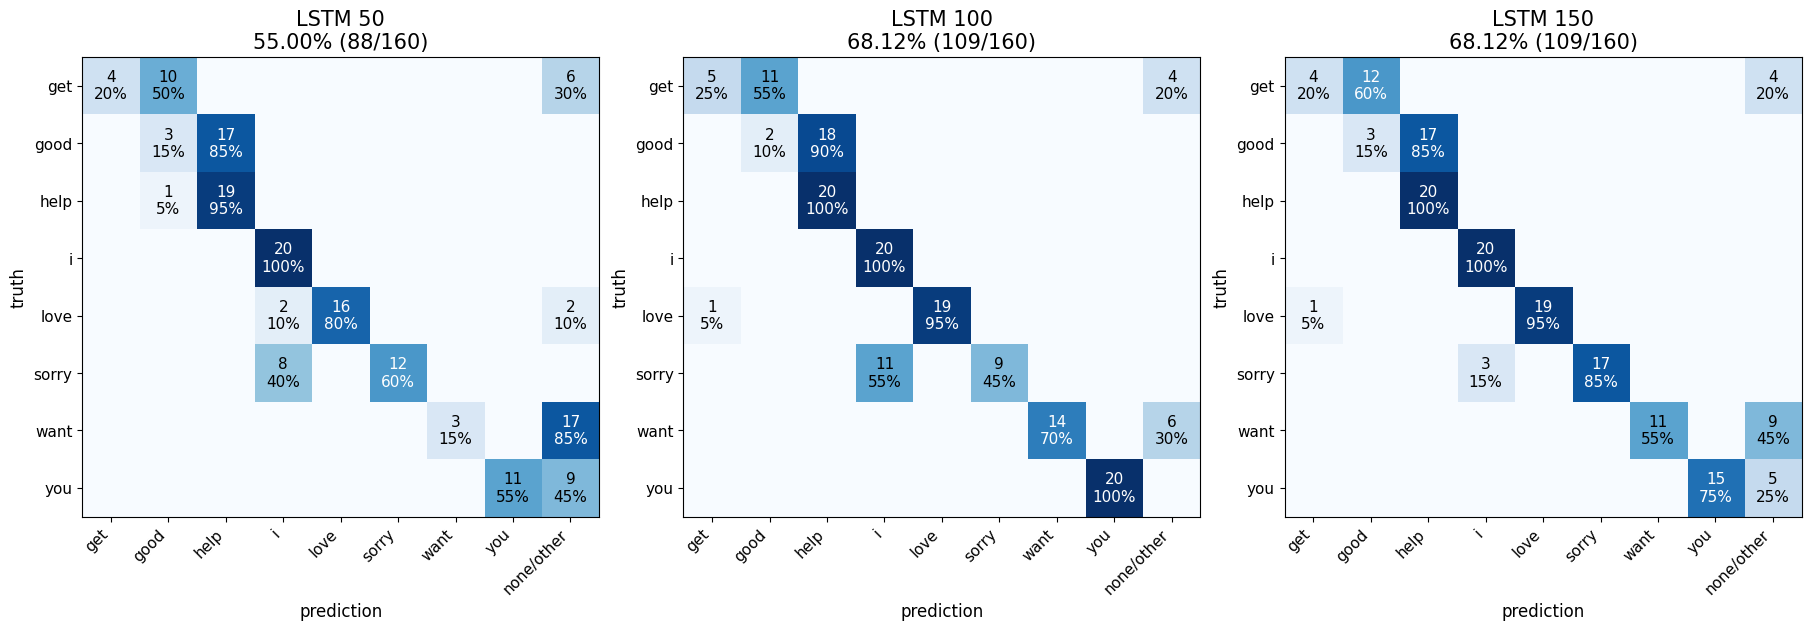

Transformer body-plus-hands confusion matrix image saved: C:\Sean Su\NUS_Project\VisionSpeak\models\SX\reports\sign_language_mediapipe_transformer_confusion.png


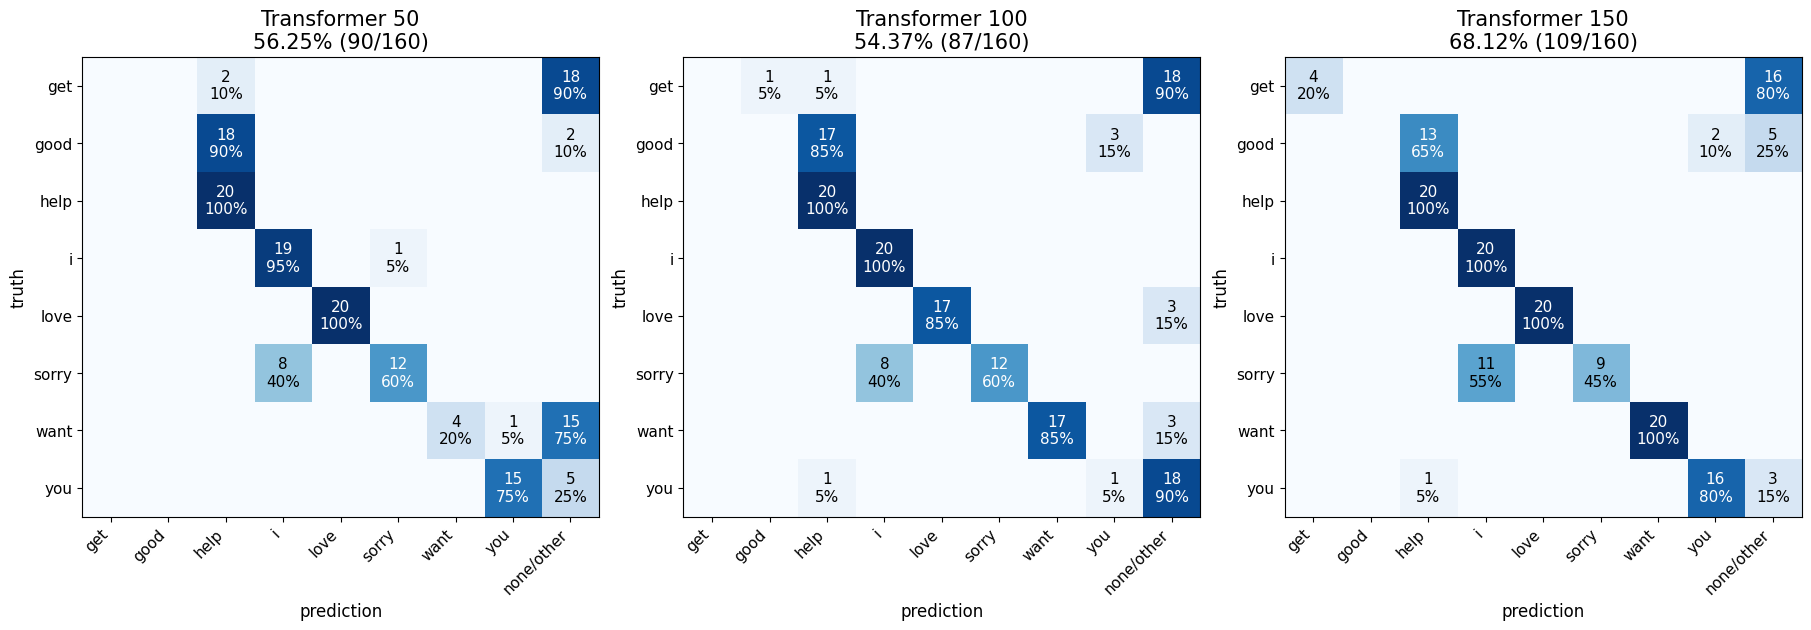

In [1]:
# Offline evaluation of the six SX checkpoints on filename-labeled test images.
from pathlib import Path
import re
import sys

PROJECT_ROOT = next(
    (
        parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (parent / 'models' / 'SX' / 'train.py').is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Could not find the VisionSpeak project root from the current working directory.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from models.SX.inference import choose_device, load_sx_checkpoint
from models.SX.train import SignLanguageWindowDataset, cache_landmarks

TEST_IMAGE_DIR = PROJECT_ROOT / 'models' / 'Lawrence' / 'test_selfie' / 'images'
LANDMARK_CACHE_DIR = PROJECT_ROOT / '.cache' / 'sx_test_selfie_landmarks'
REPORT_DIR = PROJECT_ROOT / 'models' / 'SX' / 'reports'
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

CHECKPOINTS = [
    ('LSTM 50', PROJECT_ROOT / 'checkpoints' / 'retrain' / 'Sign_Language_MediaPipe_LSTM_50.pt'),
    ('LSTM 100', PROJECT_ROOT / 'checkpoints' / 'retrain' / 'Sign_Language_MediaPipe_LSTM_100.pt'),
    ('LSTM 150', PROJECT_ROOT / 'checkpoints' / 'retrain' / 'Sign_Language_MediaPipe_LSTM_150.pt'),
    ('Transformer 50', PROJECT_ROOT / 'checkpoints' / 'retrain' / 'Sign_Language_MediaPipe_Transformer_50.pt'),
    ('Transformer 100', PROJECT_ROOT / 'checkpoints' / 'retrain' / 'Sign_Language_MediaPipe_Transformer_100.pt'),
    ('Transformer 150', PROJECT_ROOT / 'checkpoints' / 'retrain' / 'Sign_Language_MediaPipe_Transformer_150.pt'),
]

if not TEST_IMAGE_DIR.is_dir():
    raise FileNotFoundError(f'Test image directory not found: {TEST_IMAGE_DIR}')

image_paths = sorted(
    path for path in TEST_IMAGE_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)
if not image_paths:
    raise FileNotFoundError(f'No supported test images found in {TEST_IMAGE_DIR}')


def label_from_filename(image_path):
    match = re.fullmatch(r'(.+)_\d+', image_path.stem)
    if match is None:
        raise ValueError(
            f'Expected an image filename like get_01.jpg, got {image_path.name}'
        )
    return match.group(1).lower()


true_words = [label_from_filename(path) for path in image_paths]
evaluation_words = sorted(set(true_words))
if len(evaluation_words) < 2:
    raise ValueError(f'Expected multiple test classes, found {evaluation_words}')
test_samples = list(zip(image_paths, true_words))

missing_checkpoints = [path for _, path in CHECKPOINTS if not path.is_file()]
if missing_checkpoints:
    raise FileNotFoundError(
        'Missing SX checkpoints:\n' + '\n'.join(str(path) for path in missing_checkpoints)
    )

device = choose_device('auto')
reference_model, _, reference_config = load_sx_checkpoint(CHECKPOINTS[0][1], device)
del reference_model
if not reference_config.two_hands or not reference_config.use_body_pose:
    raise ValueError('This evaluation expects checkpoints trained with two hands and body pose.')
if reference_config.input_size != 225:
    raise ValueError(f'Expected 225 input features, got {reference_config.input_size}.')

# Cache MediaPipe extraction once, outside Lawrence's dataset folder.
detected, missing = cache_landmarks(
    test_samples,
    LANDMARK_CACHE_DIR,
    two_hands=reference_config.two_hands,
    sequence_length=1,
    use_body_pose=reference_config.use_body_pose,
)
print(f'Test images: {len(image_paths)} across {len(evaluation_words)} classes: {evaluation_words}')
print(f'MediaPipe landmarks detected: {detected}; all-zero feature vectors: {missing}')
print(f'Device: {device}')

reports = []
for model_name, checkpoint_path in CHECKPOINTS:
    model, class_to_idx, config = load_sx_checkpoint(checkpoint_path, device)
    if (config.input_size, config.two_hands, config.use_body_pose) != (
        reference_config.input_size,
        reference_config.two_hands,
        reference_config.use_body_pose,
    ):
        raise ValueError(f'{checkpoint_path.name} has a different landmark layout.')

    expected_architecture = 'transformer' if model_name.startswith('Transformer') else 'lstm'
    if config.architecture != expected_architecture:
        raise ValueError(
            f'{checkpoint_path.name} declares architecture {config.architecture!r}; '
            f'expected {expected_architecture!r}.'
        )

    normalized_class_to_idx = {name.lower(): index for name, index in class_to_idx.items()}
    if len(normalized_class_to_idx) != len(class_to_idx):
        raise ValueError(f'{checkpoint_path.name} has class names that collide after lowercasing.')
    unknown_words = sorted(set(evaluation_words) - set(normalized_class_to_idx))
    if unknown_words:
        raise ValueError(f'{checkpoint_path.name} does not contain test classes: {unknown_words}')
    idx_to_word = {index: name for name, index in normalized_class_to_idx.items()}

    dataset = SignLanguageWindowDataset(
        test_samples,
        normalized_class_to_idx,
        two_hands=config.two_hands,
        window_size=config.window_size,
        cache_dir=LANDMARK_CACHE_DIR,
        use_body_pose=config.use_body_pose,
        augment=False,
    )
    loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)
    word_to_row = {word: index for index, word in enumerate(evaluation_words)}
    matrix = np.zeros((len(evaluation_words), len(evaluation_words) + 1), dtype=int)
    sample_offset = 0

    model.eval()
    with torch.inference_mode():
        for sequences, _ in loader:
            predictions = model(sequences.to(device)).argmax(dim=1).cpu().tolist()
            batch_words = true_words[sample_offset:sample_offset + len(predictions)]
            for actual_word, predicted_id in zip(batch_words, predictions):
                predicted_word = idx_to_word[predicted_id]
                column = word_to_row.get(predicted_word, len(evaluation_words))
                matrix[word_to_row[actual_word], column] += 1
            sample_offset += len(predictions)

    accuracy = sum(matrix[index, index] for index in range(len(evaluation_words))) / len(true_words)
    reports.append({'name': model_name, 'matrix': matrix, 'accuracy': accuracy})
    print(f'{model_name:<16} accuracy: {accuracy:.2%} ({round(accuracy * len(true_words))}/{len(true_words)})')
    del model


def render_confusion(axis, matrix, labels, title):
    """Render a truth-normalized Blues heatmap with count and row share."""
    row_totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(
        matrix,
        row_totals,
        out=np.zeros_like(matrix, dtype=float),
        where=row_totals > 0,
    )
    axis.imshow(normalized, cmap='Blues', vmin=0.0, vmax=1.0, interpolation='nearest')
    columns = labels + ['none/other']
    axis.set_xticks(range(len(columns)), columns, rotation=45, ha='right')
    axis.set_yticks(range(len(labels)), labels)
    axis.set_xlabel('prediction', fontsize=12)
    axis.set_ylabel('truth', fontsize=12)
    axis.tick_params(axis='both', labelsize=11)
    axis.set_title(title, fontsize=15)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            count = int(matrix[row, column])
            if count == 0:
                continue
            share = normalized[row, column]
            axis.text(
                column,
                row,
                f'{count}\n{share:.0%}',
                ha='center',
                va='center',
                fontsize=11,
                color='white' if share > 0.55 else 'black',
            )


REPORT_DIR.mkdir(parents=True, exist_ok=True)
for architecture_name in ('LSTM', 'Transformer'):
    architecture_reports = [
        report for report in reports
        if report['name'].startswith(f'{architecture_name} ')
    ]
    if len(architecture_reports) != 3:
        raise ValueError(
            f'Expected three {architecture_name} checkpoints, found {len(architecture_reports)}.'
        )

    figure, axes = plt.subplots(
        1, 3, figsize=(18, 6), squeeze=False, constrained_layout=True,
    )
    for axis, report in zip(axes[0], architecture_reports):
        correct = sum(
            report['matrix'][index, index]
            for index in range(len(evaluation_words))
        )
        render_confusion(
            axis,
            report['matrix'],
            evaluation_words,
            f"{report['name']}\n{report['accuracy']:.2%} ({correct}/{len(true_words)})",
        )

    report_path = REPORT_DIR / f'sign_language_mediapipe_{architecture_name.lower()}_confusion.png'
    figure.savefig(report_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f'{architecture_name} body-plus-hands confusion matrix image saved: {report_path}')
    plt.show()
    plt.close(figure)